# Marker-Based Augmented Reality

---

- **Author:** Atta Ul Haleem  
- **Date:** November 15, 2026  
- **Professor:** Dr. Nicolas Rougon  
- **Course:** Basic Computer Vision  
- **Program:** M2 Virtual & Augmented Reality

---

## 1. Introduction

The goal is to find a planar marker (e.g., a book cover) in the webcam stream and to replace it with a substitute image. The pipeline has the four blocks of the assignment:

| Block | Role | Options compared |
| --- | --- | --- |
| 1. Descriptor extraction | Detect keypoints and describe them | SIFT, ORB, AKAZE, BRISK |
| 2. Descriptor matching | Find the nearest frame descriptors of each marker descriptor | BF, BF_CROSS, FLANN |
| 3. Match filtering | Remove the matches that are probably wrong | LOCAL (ratio test), GLOBAL (distance threshold) |
| 4. Alignment and augmentation | Estimate the homography, then warp and blend the substitute | RANSAC, LEAST_SQUARES, LMEDS, PROSAC |

The live app with its GUI is `ar_app.py` (see `README.md`). This notebook is the report: it runs the same pipeline on saved camera frames, shows each block, compares the options and explains my choices.

**Final configuration:** SIFT + BF + LOCAL (ratio 0.7) + RANSAC (3 px).

**Setup:** MacBook M4 (16 GB), camera frames of 1920 x 1080, Python 3.10.13, OpenCV 5.0.0 (opencv-contrib-python). SURF could not be tested: it is patented and not included in this OpenCV build.

In [1]:
# Pick up edits to `.py` files without restarting kernel
%load_ext autoreload
%autoreload 2

In [2]:
# Import libraries
import cv2 as cv
from IPython.display import Markdown, display

In [3]:
# Import modules
import benchmark
import config
import estimators
import pipeline
import utils

---

## 2. Inputs

The marker is a book cover. The substitute is cropped and resized to the size of the marker, so the same homography places it in the frame. The frame below is used to show each block.

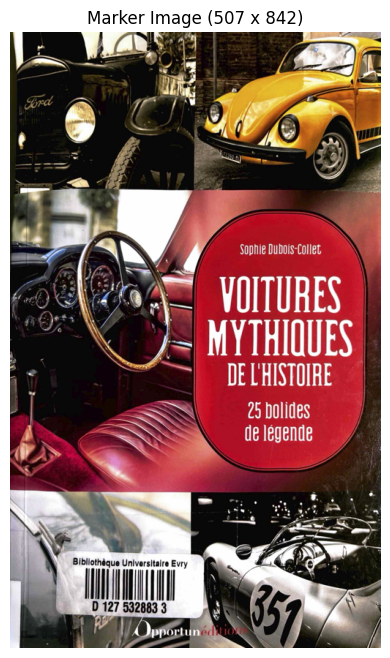

In [4]:
# Marker image
marker = utils.load_image(config.MARKER_PATH)
marker = utils.shrink_to_max_side(marker, config.MARKER_MAX_SIDE)
utils.plot_image(marker, f"Marker Image ({marker.shape[1]} x {marker.shape[0]})")

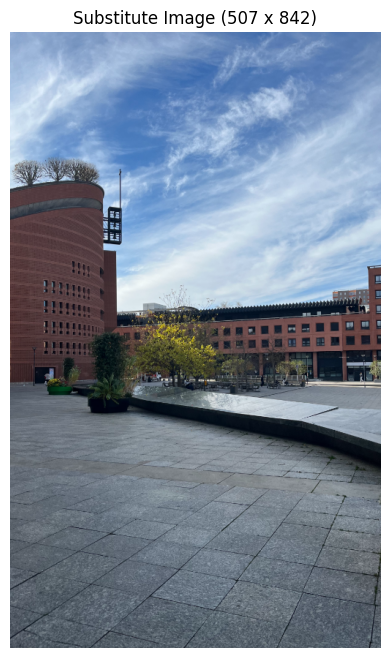

In [5]:
# Substitute image
substitute = utils.load_image(config.SUBSTITUTE_PATH)
substitute = utils.center_crop_to_size(substitute, marker.shape[1], marker.shape[0])
utils.plot_image(
    substitute, f"Substitute Image ({substitute.shape[1]} x {substitute.shape[0]})"
)

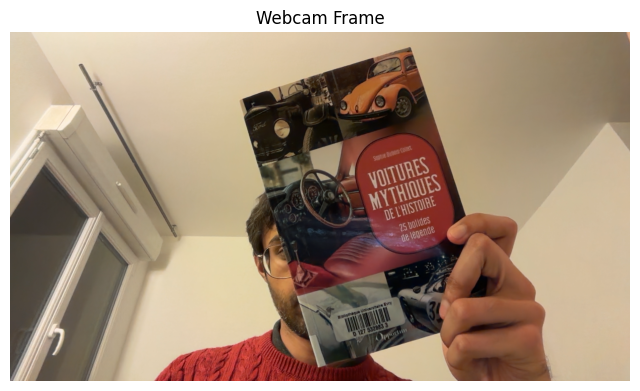

In [6]:
# Camera frame
if config.CAPTURE_NEW_FRAME:
    cv.imwrite(config.FRAME_PATH, utils.grab_frame(config.CAMERA_INDEX))
frame = utils.load_image(config.FRAME_PATH)
utils.plot_image(frame, "Webcam Frame")

---

## 3. Benchmark Frames

To compare the options, I saved 12 camera frames, one per condition. The last three show weaker markers. Each comparison changes one block and keeps the others at the final configuration. The tables report:

- **Found:** the number of frames where the marker is found (at least 15 inliers).
- **Not Found:** the frames where it is not.
- **Inliers:** the matches that agree with the homography (within 3 px), on average per frame.
- **Inlier Share:** the part of the filtered matches that are inliers.
- **Time:** the average time of the pipeline per frame.

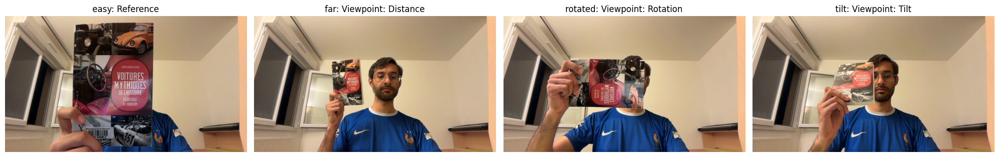

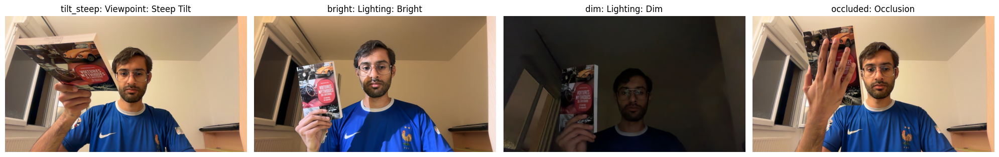

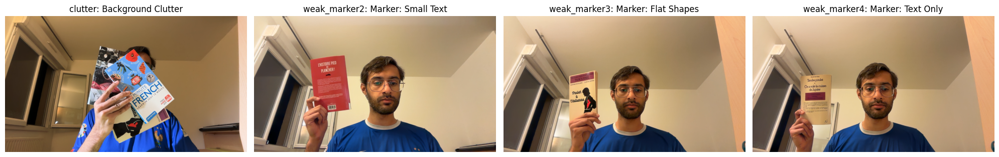

In [7]:
# Benchmark frames: one saved camera frame per condition
benchmark_images = benchmark.load_benchmark_images(
    config.BENCHMARK_FRAMES, config.MARKER_MAX_SIDE
)

# The final configuration, which every comparison starts from
baseline_names = {
    "detector": config.DETECTOR_NAME,
    "matcher": config.MATCHER_NAME,
    "filter": config.FILTER_NAME,
    "estimator": config.ESTIMATOR_NAME,
}

images_per_row = 4
benchmark_frame_images = []
benchmark_frame_titles = []
for frame_name, (benchmark_marker, benchmark_frame) in benchmark_images.items():
    benchmark_frame_images.append(benchmark_frame)
    benchmark_frame_titles.append(
        f"{frame_name}: {config.BENCHMARK_FRAMES[frame_name]['condition']}"
    )

utils.plot_image_grid(benchmark_frame_images, benchmark_frame_titles, images_per_row)

---

## 4. Block 1: Descriptor Extraction

A good keypoint is found again when the marker is seen from another distance or angle, and its descriptor is distinctive enough to be matched. I compared four detectors with `detectAndCompute`:

- **SIFT:** a float descriptor (histograms of gradient orientations), compared with the L2 distance.
- **ORB, AKAZE, BRISK:** binary descriptors, compared with the Hamming distance. They are designed to be faster.

All four choose a scale and an orientation for each keypoint. The circles below show them.

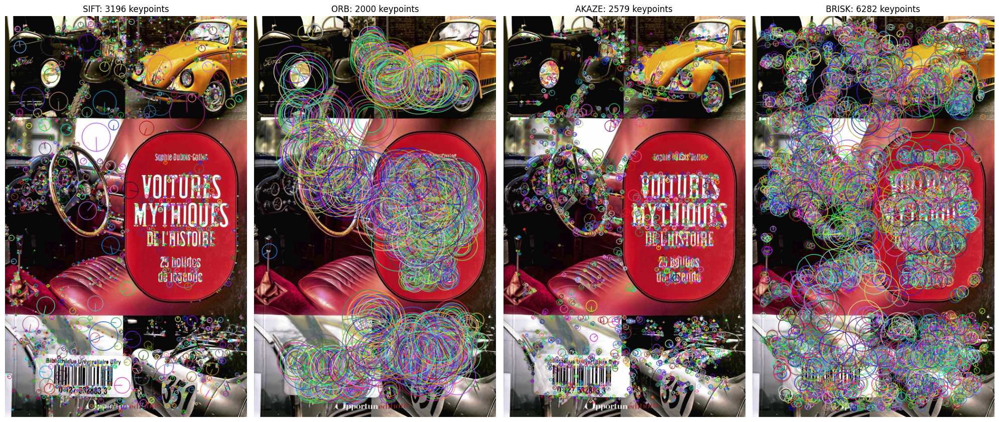

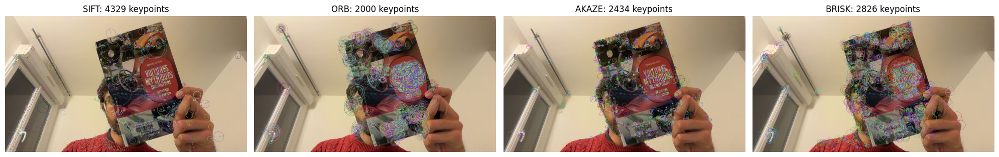

In [8]:
# Image descriptor extraction: every registered detector
marker_features = {}
frame_features = {}

marker_keypoint_images = []
marker_keypoint_titles = []
frame_keypoint_images = []
frame_keypoint_titles = []

for detector_name in config.DETECTORS:
    detector = pipeline.build_detector(detector_name)

    # Marker keypoints
    marker_keypoints, marker_descriptors = pipeline.apply_detector(detector, marker)
    marker_features[detector_name] = (marker_keypoints, marker_descriptors)
    marker_keypoint_images.append(utils.draw_keypoints(marker, marker_keypoints))
    marker_keypoint_titles.append(f"{detector_name}: {len(marker_keypoints)} keypoints")

    # Frame keypoints
    frame_keypoints, frame_descriptors = pipeline.apply_detector(detector, frame)
    frame_features[detector_name] = (frame_keypoints, frame_descriptors)
    frame_keypoint_images.append(utils.draw_keypoints(frame, frame_keypoints))
    frame_keypoint_titles.append(f"{detector_name}: {len(frame_keypoints)} keypoints")

utils.plot_image_row(marker_keypoint_images, marker_keypoint_titles)
utils.plot_image_row(frame_keypoint_images, frame_keypoint_titles)

marker_keypoints, marker_descriptors = marker_features[config.DETECTOR_NAME]
frame_keypoints, frame_descriptors = frame_features[config.DETECTOR_NAME]

The keypoints lie on the textured parts of the cover. The table below runs the whole pipeline with each detector on the benchmark frames.

In [9]:
# Detector comparison
detector_measurements = benchmark.measure_techniques(
    benchmark_images,
    baseline_names,
    "detector",
    config.DETECTORS,
    config.BENCHMARK_MAX_ERROR,
)
display(
    Markdown(
        utils.format_table(
            benchmark.build_summary_rows("Detector", detector_measurements)
        )
    )
)

| Detector | Found | Not Found | Inliers | Inlier Share | Time (ms) |
| --- | --- | --- | --- | --- | --- |
| SIFT | 11 / 12 | tilt_steep | 180 | 73% | 64 |
| ORB | 10 / 12 | tilt, tilt_steep | 78 | 85% | 15 |
| AKAZE | 9 / 12 | tilt, tilt_steep, weak_marker4 | 78 | 78% | 76 |
| BRISK | 11 / 12 | tilt_steep | 102 | 73% | 38 |

- SIFT is the most robust: it has the most inliers and only loses the steep tilt, which no detector finds.
- ORB is about four times faster, but it has less than half the inliers and also loses the `tilt` frame.
- BRISK is in between. AKAZE is the slowest and loses three frames.

**Choice: SIFT.** About 55 ms per frame is still interactive, so I preferred robustness over speed. ORB and BRISK can be selected in the GUI when speed matters more.

The most important setting of this block is the number of keypoints. The next table limits SIFT to its strongest keypoints (0 keeps them all).

In [10]:
# Number of SIFT keypoints
sweep_measurements = benchmark.measure_sweep(
    benchmark_images,
    baseline_names,
    config.BENCHMARK_SWEEPS["Features"],
    config.BENCHMARK_MAX_ERROR,
)
display(
    Markdown(
        utils.format_table(benchmark.build_summary_rows("Features", sweep_measurements))
    )
)

| Features | Found | Not Found | Inliers | Inlier Share | Time (ms) |
| --- | --- | --- | --- | --- | --- |
| 500 | 10 / 12 | tilt_steep, clutter | 49 | 72% | 46 |
| 1000 | 11 / 12 | tilt_steep | 84 | 69% | 49 |
| 2000 | 11 / 12 | tilt_steep | 145 | 72% | 59 |
| 0 | 11 / 12 | tilt_steep | 180 | 73% | 70 |

With 500 keypoints the inliers drop from 180 to 49 and the `clutter` frame is lost, but the time only drops from about 55 to 40 ms: SIFT builds its whole scale space before it keeps the strongest keypoints. So I keep all the keypoints.

---

## 5. Block 2: Descriptor Matching

For each marker descriptor, the matcher returns its two nearest frame descriptors (`knnMatch` with k = 2). The second one is needed by the ratio test of the next block. I compared three matchers:

- **BF:** brute force. It compares every pair of descriptors, so the result is exact.
- **BF_CROSS:** brute force with cross-check. It keeps a match only if it is the best in both directions. It returns one candidate, so only the GLOBAL filter can follow.
- **FLANN:** an approximate search, designed for large sets of descriptors.

3196 marker descriptors matched


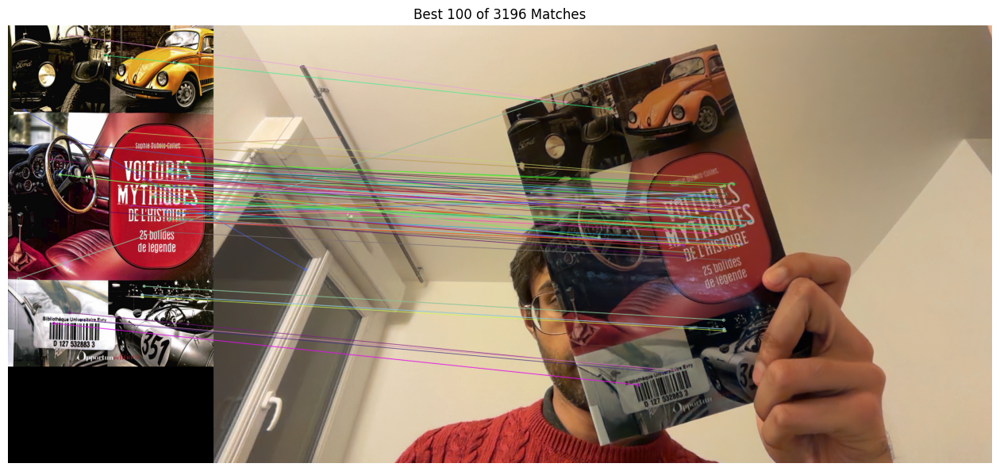

In [11]:
# Descriptor matching
matcher = pipeline.build_matcher(config.MATCHER_NAME, config.DETECTOR_NAME)
knn_matches = pipeline.apply_matcher(matcher, marker_descriptors, frame_descriptors)
print(f"{len(knn_matches)} marker descriptors matched")

# Plot only the closest matches
best_matches = utils.select_best_matches(knn_matches)
shown_match_count = 100
utils.plot_matches(
    marker,
    marker_keypoints,
    frame,
    frame_keypoints,
    best_matches[:shown_match_count],
    f"Best {shown_match_count} of {len(best_matches)} Matches",
)

The 100 closest matches are mostly correct. But every marker descriptor gets a match, even when its keypoint is not visible in the frame, so many of the others are wrong. The table compares the matchers, each with the filters that can use its matches.

In [12]:
# Matcher comparison: each matcher with every filter that can use its matches
matcher_measurements = {}
for matcher_name in config.MATCHERS:
    for filter_name in config.get_valid_filter_names(matcher_name):
        technique_names = {
            **baseline_names,
            "matcher": matcher_name,
            "filter": filter_name,
        }
        matcher_measurements[f"{matcher_name} + {filter_name}"] = (
            benchmark.measure_frames(
                benchmark_images, technique_names, config.BENCHMARK_MAX_ERROR
            )
        )

display(
    Markdown(
        utils.format_table(
            benchmark.build_summary_rows("Matcher + Filter", matcher_measurements)
        )
    )
)

| Matcher + Filter | Found | Not Found | Inliers | Inlier Share | Time (ms) |
| --- | --- | --- | --- | --- | --- |
| BF + LOCAL | 11 / 12 | tilt_steep | 180 | 73% | 68 |
| BF + GLOBAL | 10 / 12 | tilt, tilt_steep | 87 | 53% | 68 |
| BF_CROSS + GLOBAL | 8 / 12 | tilt, tilt_steep, dim, clutter | 61 | 65% | 88 |
| FLANN + LOCAL | 11 / 12 | tilt_steep | 181 | 71% | 80 |
| FLANN + GLOBAL | 10 / 12 | tilt, tilt_steep | 98 | 54% | 79 |

- BF and FLANN find the same frames with almost the same inliers, but FLANN is slower here. It builds a new index for every frame, and a few thousand descriptors are too few for that to pay off.
- BF_CROSS is slower and finds fewer frames.
- With both matchers, the LOCAL filter does better than GLOBAL (see the next block).

**Choice: BF.** It is exact, the fastest here, and has no settings.

---

## 6. Block 3: Match Filtering

The filter removes the wrong matches by looking at the descriptor distances. I compared the two strategies of the assignment:

- **GLOBAL:** keeps a match if its distance is below a fraction of the largest distance in the frame.
- **LOCAL (ratio test):** keeps a match if it is clearly better than the second-best candidate: $d_1 < r \cdot d_2$. A correct match has one close candidate. A wrong one usually has several candidates at similar distances.

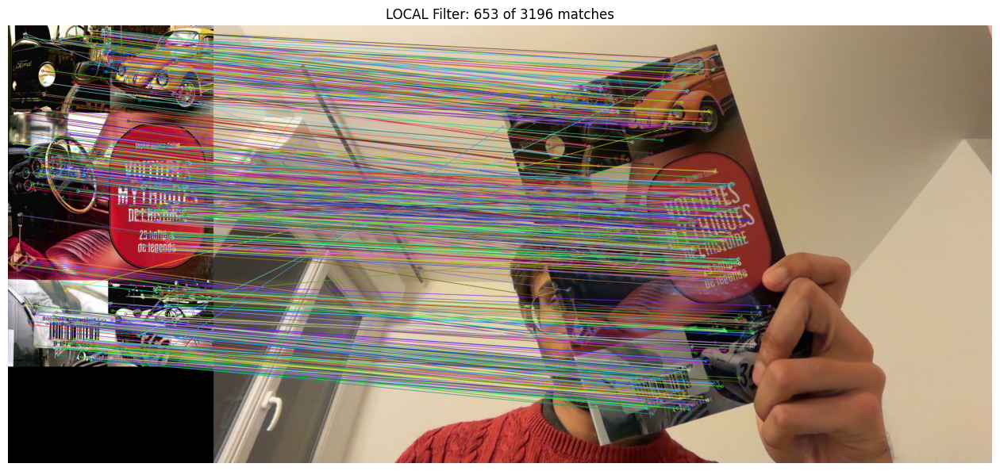

In [13]:
# Match filtering
match_filter = pipeline.build_filter(config.FILTER_NAME)
filtered_matches = pipeline.apply_filter(match_filter, knn_matches)
utils.plot_matches(
    marker,
    marker_keypoints,
    frame,
    frame_keypoints,
    filtered_matches,
    f"{config.FILTER_NAME} Filter: {len(filtered_matches)} of {len(knn_matches)} matches",
)

After the filter, almost all the remaining matches end on the cover. The two tables below vary the setting of each filter.

In [14]:
# Ratio of the LOCAL filter
sweep_measurements = benchmark.measure_sweep(
    benchmark_images,
    baseline_names,
    config.BENCHMARK_SWEEPS["Ratio"],
    config.BENCHMARK_MAX_ERROR,
)
display(
    Markdown(
        utils.format_table(benchmark.build_summary_rows("Ratio", sweep_measurements))
    )
)

| Ratio | Found | Not Found | Inliers | Inlier Share | Time (ms) |
| --- | --- | --- | --- | --- | --- |
| 0.5 | 10 / 12 | tilt, tilt_steep | 84 | 84% | 53 |
| 0.6 | 11 / 12 | tilt_steep | 126 | 78% | 55 |
| 0.7 | 11 / 12 | tilt_steep | 180 | 73% | 55 |
| 0.8 | 11 / 12 | tilt_steep | 222 | 57% | 57 |
| 0.9 | 11 / 12 | tilt_steep | 263 | 32% | 65 |

In [15]:
# Fraction of the GLOBAL filter
sweep_measurements = benchmark.measure_sweep(
    benchmark_images,
    baseline_names,
    config.BENCHMARK_SWEEPS["Fraction"],
    config.BENCHMARK_MAX_ERROR,
)
display(
    Markdown(
        utils.format_table(benchmark.build_summary_rows("Fraction", sweep_measurements))
    )
)

| Fraction | Found | Not Found | Inliers | Inlier Share | Time (ms) |
| --- | --- | --- | --- | --- | --- |
| 0.3 | 10 / 12 | tilt, tilt_steep | 87 | 53% | 59 |
| 0.4 | 11 / 12 | tilt_steep | 158 | 43% | 59 |
| 0.6 | 11 / 12 | tilt_steep | 261 | 25% | 67 |
| 0.8 | 10 / 12 | tilt_steep, clutter | 266 | 11% | 74 |

- **LOCAL:** a lower ratio gives cleaner matches, but fewer of them. From 0.6 to 0.9 the same 11 frames are found, so the value is not critical.
- **GLOBAL:** no fraction works well. A low one loses frames, and a high one lets in mostly wrong matches (11% inliers at 0.8). The threshold depends on the worst match of the frame, which changes with the background.

**Choice: LOCAL with a ratio of 0.7.** About three quarters of the kept matches are inliers, and no frame is lost.

---

## 7. Block 4: Alignment and Augmentation

### 7.1 Homography

The marker is planar, so the marker image and its view in the frame are related by a homography $H$: a 3 x 3 matrix that needs at least four matches. `findHomography` offers four methods:

- **LEAST_SQUARES:** uses all the matches, including the wrong ones.
- **RANSAC:** tries random groups of four matches and keeps the $H$ that most matches agree with.
- **LMEDS:** keeps the $H$ with the smallest median error. It needs more than half of the matches to be correct.
- **PROSAC:** a faster variant of RANSAC that tries the best matches first.

The app accepts $H$ only if at least 15 matches agree with it, so nothing is drawn when the marker is not visible.

RANSAC: 553 of 653 matches are inliers
LEAST_SQUARES: 45 of 653 matches are inliers
LMEDS: 556 of 653 matches are inliers
PROSAC: 334 of 653 matches are inliers
[[ 9.88116612e-01  2.73941065e-01  7.07432716e+02]
 [-3.39712830e-01  9.35136306e-01  2.14667936e+02]
 [-5.05058975e-05 -2.65770428e-05  1.00000000e+00]]


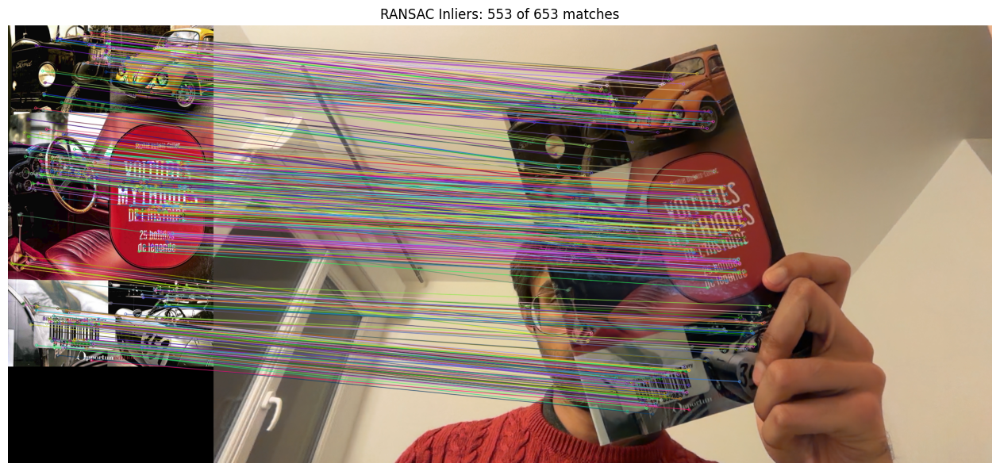

In [16]:
# Homography estimation: every registered estimator
homographies = {}
inlier_matches_by_estimator = {}

for estimator_name in config.ESTIMATORS:
    estimator = pipeline.build_estimator(estimator_name)
    try:
        homography, inlier_mask = pipeline.apply_estimator(
            estimator, marker_keypoints, frame_keypoints, filtered_matches
        )
    except estimators.HomographyNotFoundError as error:
        print(f"{estimator_name}: not found. {error}")
        continue

    inlier_matches = utils.select_inlier_matches(filtered_matches, inlier_mask)
    homographies[estimator_name] = homography
    inlier_matches_by_estimator[estimator_name] = inlier_matches
    print(
        f"{estimator_name}: {len(inlier_matches)} of {len(filtered_matches)} matches are inliers"
    )

homography = homographies[config.ESTIMATOR_NAME]
inlier_matches = inlier_matches_by_estimator[config.ESTIMATOR_NAME]
print(homography)

# Plot only the matches that agree with the homography
utils.plot_matches(
    marker,
    marker_keypoints,
    frame,
    frame_keypoints,
    inlier_matches,
    f"{config.ESTIMATOR_NAME} Inliers: {len(inlier_matches)} of {len(filtered_matches)} matches",
)

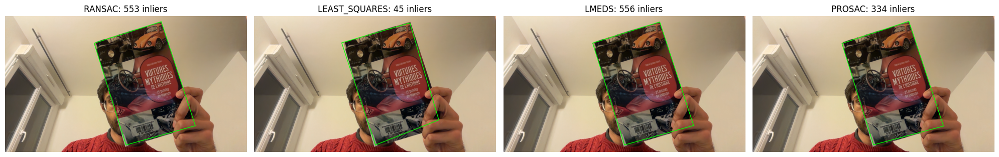

In [17]:
# Marker outline: every estimator that found a homography
outline_images = []
outline_titles = []

for estimator_name, estimator_homography in homographies.items():
    frame_corners = utils.project_corners(estimator_homography, marker)
    outline_images.append(utils.draw_outline(frame, frame_corners))
    inlier_count = len(inlier_matches_by_estimator[estimator_name])
    outline_titles.append(f"{estimator_name}: {inlier_count} inliers")

utils.plot_image_row(outline_images, outline_titles)

On this frame the three robust methods place the outline on the cover, and least squares is slightly off. The table compares them on the benchmark frames.

In [18]:
# Estimator comparison
estimator_measurements = benchmark.measure_techniques(
    benchmark_images,
    baseline_names,
    "estimator",
    config.ESTIMATORS,
    config.BENCHMARK_MAX_ERROR,
)
display(
    Markdown(
        utils.format_table(
            benchmark.build_summary_rows("Estimator", estimator_measurements)
        )
    )
)

| Estimator | Found | Not Found | Inliers | Inlier Share | Time (ms) |
| --- | --- | --- | --- | --- | --- |
| RANSAC | 11 / 12 | tilt_steep | 180 | 73% | 58 |
| LEAST_SQUARES | 4 / 12 | tilt, tilt_steep, dim, occluded, clutter, weak_marker2, weak_marker3, weak_marker4 | 16 | 6% | 55 |
| LMEDS | 11 / 12 | tilt_steep | 185 | 75% | 58 |
| PROSAC | 11 / 12 | tilt_steep | 158 | 64% | 55 |

- Least squares fails in most frames: about a quarter of the filtered matches are still wrong, and it uses them all.
- RANSAC and LMEDS give the same result. PROSAC finds the same frames with fewer inliers.
- The time is the same for all: the estimation is a small part of the pipeline.

**Choice: RANSAC.** It is as accurate as LMEDS, and it still works when fewer than half of the matches are correct. This happens with a loose filter: at a ratio of 0.9 only 32% of the matches are inliers, and RANSAC still finds the 11 frames.

### 7.2 Augmentation

The substitute is warped with $H$ to the size of the frame (`warpPerspective`) and blended with the frame where it covers it:

$$\text{fusion} = (1 - \alpha) \cdot H(\text{substitute}) + \alpha \cdot \text{frame}$$

With $\alpha = 0$ the marker is fully replaced. I use $\alpha = 0.2$ by default.

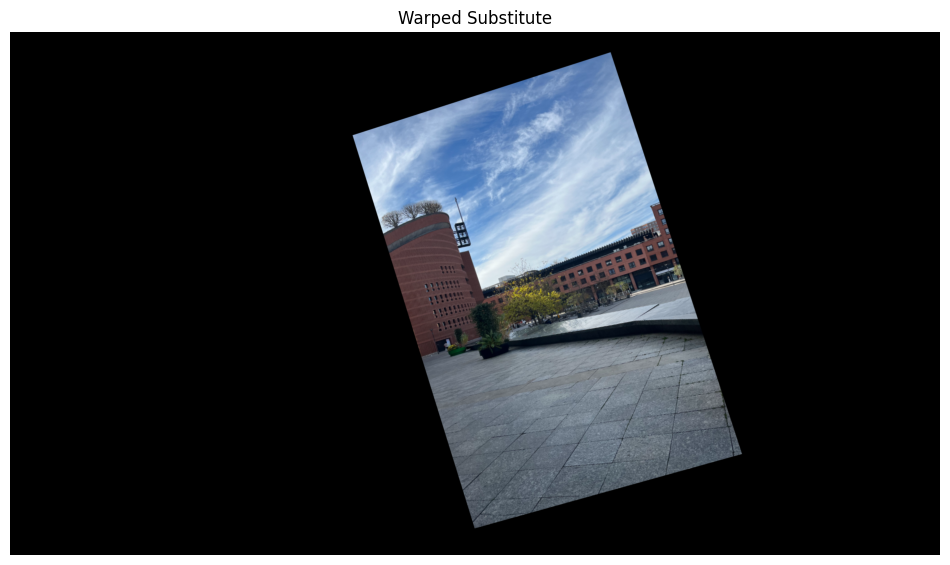

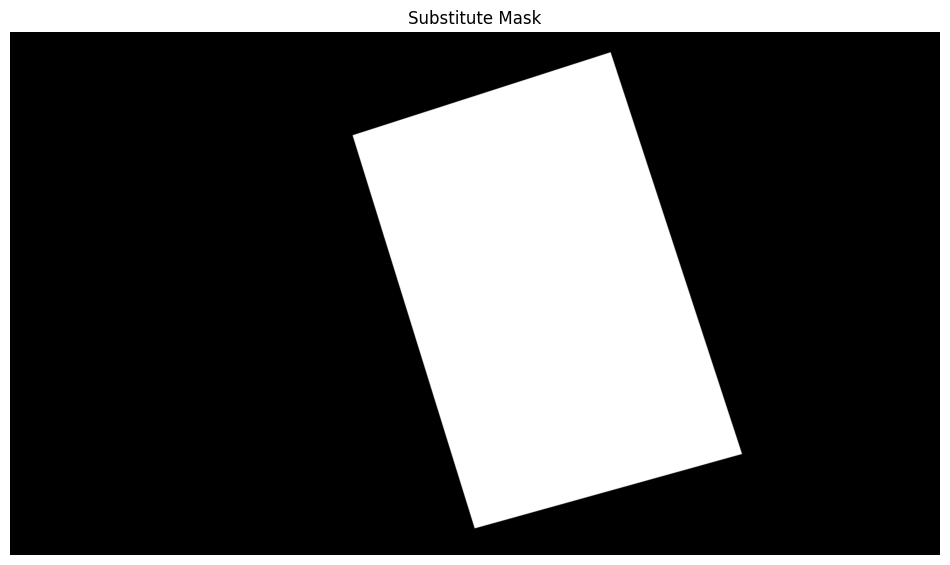

In [19]:
# Substitute warp
frame_height, frame_width = frame.shape[:2]
warped_substitute, substitute_mask = utils.warp_image(
    substitute, homography, frame_width, frame_height
)
utils.plot_image(warped_substitute, "Warped Substitute", 12)
utils.plot_image(substitute_mask, "Substitute Mask", 12)

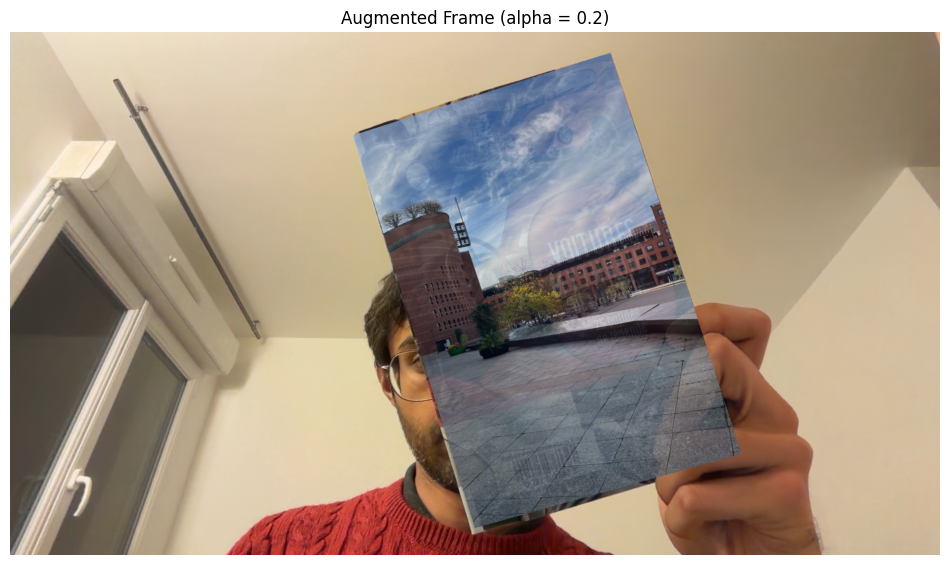

In [20]:
# Augmented frame
augmented_frame = utils.overlay_image(
    frame, warped_substitute, substitute_mask, config.FRAME_ALPHA
)
utils.plot_image(augmented_frame, f"Augmented Frame (alpha = {config.FRAME_ALPHA})", 12)

To check the registration, the last view warps the marker itself onto the frame. It lies exactly on the real cover, so $H$ is accurate.

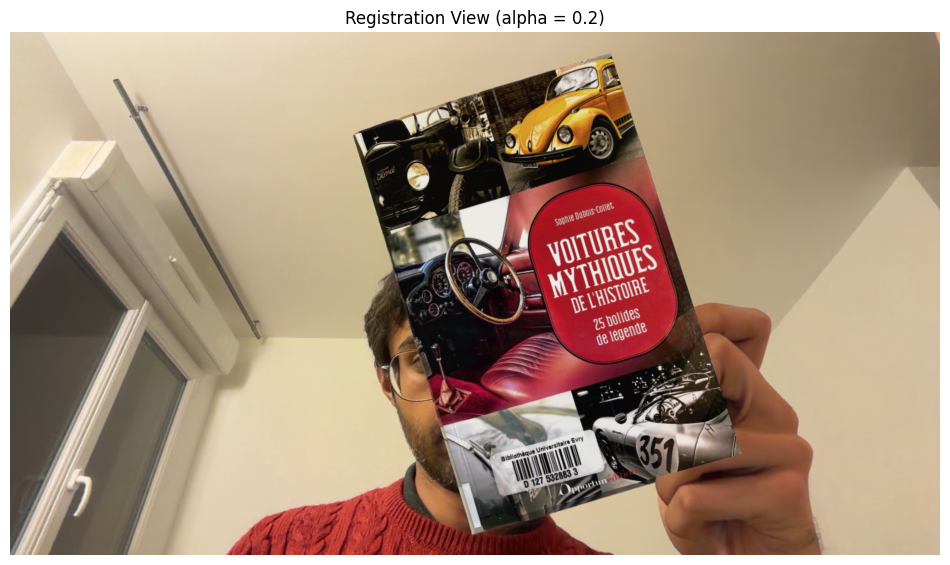

In [21]:
# Registration view: the marker itself warped onto the frame. If the
# homography is right, it lines up with the real marker (sharp, no ghosting)
warped_marker, marker_mask = utils.warp_image(
    marker, homography, frame_width, frame_height
)
registration_view = utils.overlay_image(
    frame, warped_marker, marker_mask, config.FRAME_ALPHA
)
utils.plot_image(
    registration_view, f"Registration View (alpha = {config.FRAME_ALPHA})", 12
)

---

## 8. Robustness

This section runs the final configuration on each benchmark frame. The first images show the outline of the marker where it is found, the second ones the augmented frame.

| Frame | Condition | Marker Keypoints | Frame Keypoints | Filtered | Inliers | Found |
| --- | --- | --- | --- | --- | --- | --- |
| easy | Reference | 3196 | 4027 | 750 | 495 | Yes |
| far | Viewpoint: Distance | 3196 | 2423 | 304 | 264 | Yes |
| rotated | Viewpoint: Rotation | 3196 | 2861 | 403 | 341 | Yes |
| tilt | Viewpoint: Tilt | 3196 | 2120 | 66 | 43 | Yes |
| tilt_steep | Viewpoint: Steep Tilt | 3196 | 2384 | 30 | 0 | No |
| bright | Lighting: Bright | 3196 | 3252 | 329 | 287 | Yes |
| dim | Lighting: Dim | 3196 | 753 | 135 | 85 | Yes |
| occluded | Occlusion | 3196 | 2452 | 214 | 145 | Yes |
| clutter | Background Clutter | 3196 | 4113 | 142 | 110 | Yes |
| weak_marker2 | Marker: Small Text | 1760 | 2250 | 199 | 173 | Yes |
| weak_marker3 | Marker: Flat Shapes | 1398 | 1477 | 152 | 96 | Yes |
| weak_marker4 | Marker: Text Only | 2391 | 1951 | 244 | 123 | Yes |

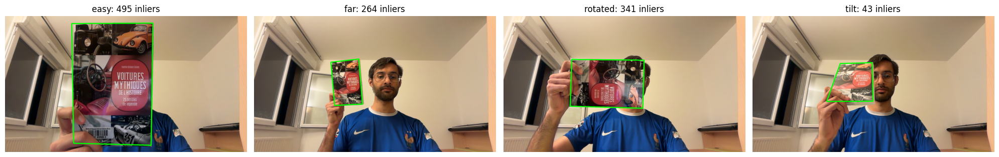

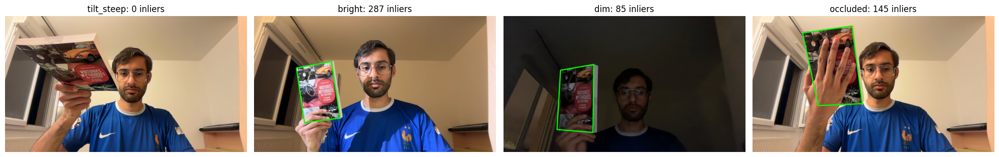

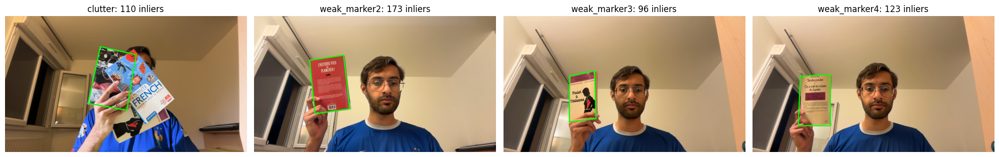

In [22]:
# Final configuration on every benchmark frame
baseline_measurements = benchmark.measure_frames(
    benchmark_images, baseline_names, config.BENCHMARK_MAX_ERROR
)
display(
    Markdown(
        utils.format_table(
            benchmark.build_frame_rows(config.BENCHMARK_FRAMES, baseline_measurements)
        )
    )
)

found_images = []
found_titles = []
for frame_name, (benchmark_marker, benchmark_frame) in benchmark_images.items():
    measurement = baseline_measurements[frame_name]
    found_images.append(
        benchmark.draw_found_marker(benchmark_marker, benchmark_frame, measurement)
    )
    found_titles.append(f"{frame_name}: {measurement.inlier_count} inliers")

utils.plot_image_grid(found_images, found_titles, images_per_row)

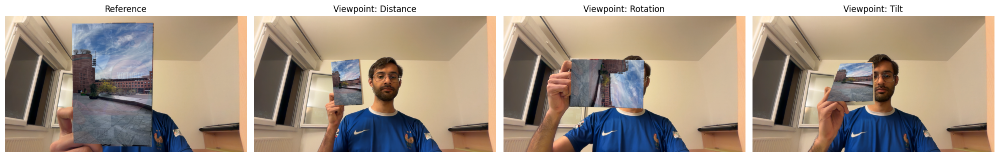

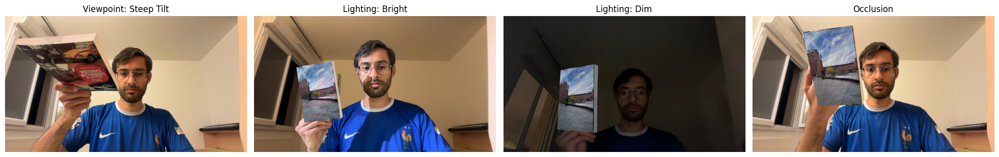

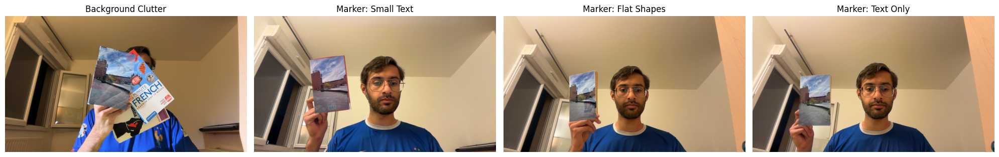

In [23]:
# Augmentation on every benchmark frame
full_substitute = utils.load_image(config.SUBSTITUTE_PATH)

augmented_images = []
augmented_titles = []
for frame_name, (benchmark_marker, benchmark_frame) in benchmark_images.items():
    measurement = baseline_measurements[frame_name]
    augmented_images.append(
        benchmark.draw_augmented_frame(
            benchmark_marker,
            full_substitute,
            benchmark_frame,
            measurement,
            config.FRAME_ALPHA,
        )
    )
    augmented_titles.append(config.BENCHMARK_FRAMES[frame_name]["condition"])

utils.plot_image_grid(augmented_images, augmented_titles, images_per_row)

The marker is found in 11 of the 12 frames. Each outline lies on the cover, and the substitute follows the marker in distance, rotation and tilt.

- **Marker features:** the weaker markers (small text, flat shapes, text only) give fewer keypoints and fewer inliers than the main marker at a similar distance (96 to 173, against 264 for `far`). Flat areas have no keypoints, and repeated letters look alike, so the ratio test rejects their matches. A good marker has texture everywhere and no repeated pattern.
- **Viewpoint:** distance and rotation are handled well (264 and 341 inliers), thanks to the scale and the orientation of the keypoints. Tilt is the weak point: 43 inliers remain on `tilt`, and the steep tilt is not found. SIFT does not correct the deformation of a tilted plane.
- **Lighting:** in the dim frame the detector finds far fewer keypoints (753), but the marker is still found with 85 inliers. Low light reduces the number of keypoints more than the quality of the matches.
- **Occlusion:** with a hand on the cover, 145 inliers remain. Each keypoint is matched on its own, so the visible part is enough. The substitute is drawn over the hand, because the app does not know which part of the marker is hidden.
- **Background:** the cluttered frame has the most keypoints (4113), but the filter and RANSAC remove their matches, and the marker is found with 110 inliers.

---

## 9. Conclusion

| Block | Choice | Settings |
| --- | --- | --- |
| 1. Descriptor extraction | SIFT | All keypoints |
| 2. Descriptor matching | BF | L2 distance, two nearest neighbours |
| 3. Match filtering | LOCAL | Ratio 0.7 |
| 4. Alignment | RANSAC | 3 px, at least 15 inliers |
| 4. Augmentation | Linear blending | $\alpha = 0.2$ |

The table below gives the average time of each stage with this configuration.

In [24]:
# Time per stage of the final configuration
display(Markdown(utils.format_table(benchmark.build_time_rows(baseline_measurements))))

| Stage | Time (ms) |
| --- | --- |
| Detector | 44.2 |
| Matcher | 10.5 |
| Filter | 0.3 |
| Estimator | 1.7 |
| Total | 56.7 |

The pipeline takes about 55 ms per frame, which is about 18 frames per second before drawing. Most of it is detection.

**GUI.** `ar_app.py` has a slider to select the technique of each block, and sliders for their main settings (number of keypoints, ratio, RANSAC threshold, minimum inliers, $\alpha$). It can show the augmented frame, the keypoints, and the matches before filtering, after filtering and after RANSAC, together with the counts and the time of each stage.

**Limits.**

- A steep tilt is not handled.
- Detection is the slow part. A smaller frame or ORB would be faster, but less robust.
- Each frame is processed on its own, so the overlay is not smoothed over time. The optional refinement step is not implemented.
- The benchmark has one frame per condition, so the numbers show tendencies only.